# 암환자 유전체 데이터 기반 암종 분류 AI 모델 개발


- 바이오 데이터를 기반으로 한 AI 기술의 문제 해결 능력을 탐구하는 것을 목표로 합니다. <br>이 대회는 바이오 분야에서 AI 활용의 저변을 확대하고, 복잡한 바이오 데이터를 효율적으로 분석 및 해석할 수 있는 AI 알고리즘 개발에 초점을 맞추고 있습니다. <br><br>
- 본 대회의 구체적인 과제는 암환자 유전체 데이터의 변이 정보를 활용하여 암종을 분류하는 AI 모델을 개발하는 것입니다. <br>참가자들은 제공된 학습 데이터셋(암환자 유전체 변이 정보)을 사용하여 특정 변이 정보를 바탕으로 암종을 정확하게 분류할 수 있는 AI 알고리즘을 개발해야 합니다. <br><br>
- 이 대회의 궁극적인 목적은 바이오 데이터의 활용도를 높이고, 바이오 분야에서 AI 기술의 적용 가능성을 극대화하며, 인공지능 기술이 실제 바이오 의료 문제 해결에 어떻게 기여할 수 있는지 탐구하는 것입니다.

# Import library

In [2]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder
import xgboost as xgb

# Load Data

In [ ]:
# 구글 드라이브 연결 — 데이터(train.csv)는 드라이브에 두고 읽는다
from google.colab import drive
drive.mount('/content/drive')

# 데이터 폴더 — 본인 드라이브 경로로 수정. 최종 제출본에서는 규정대로 '/data'로 바꾼다
DATA_DIR = '/content/drive/MyDrive/dacon_cancer/data'

train = pd.read_csv(f'{DATA_DIR}/train.csv')
test = pd.read_csv(f'{DATA_DIR}/test.csv')

# Data Preprocessing

In [19]:
# SUBCLASS 가 범주형이기 때문에 LabelEncoder 사용
le_subclass = LabelEncoder()
train['SUBCLASS'] = le_subclass.fit_transform(train['SUBCLASS'])


# 변환된 레이블 확인
for i, label in enumerate(le_subclass.classes_):
    print(f"원래 레이블: {label}, 변환된 숫자: {i}")

원래 레이블: ACC, 변환된 숫자: 0
원래 레이블: BLCA, 변환된 숫자: 1
원래 레이블: BRCA, 변환된 숫자: 2
원래 레이블: CESC, 변환된 숫자: 3
원래 레이블: COAD, 변환된 숫자: 4
원래 레이블: DLBC, 변환된 숫자: 5
원래 레이블: GBMLGG, 변환된 숫자: 6
원래 레이블: HNSC, 변환된 숫자: 7
원래 레이블: KIPAN, 변환된 숫자: 8
원래 레이블: KIRC, 변환된 숫자: 9
원래 레이블: LAML, 변환된 숫자: 10
원래 레이블: LGG, 변환된 숫자: 11
원래 레이블: LIHC, 변환된 숫자: 12
원래 레이블: LUAD, 변환된 숫자: 13
원래 레이블: LUSC, 변환된 숫자: 14
원래 레이블: OV, 변환된 숫자: 15
원래 레이블: PAAD, 변환된 숫자: 16
원래 레이블: PCPG, 변환된 숫자: 17
원래 레이블: PRAD, 변환된 숫자: 18
원래 레이블: SARC, 변환된 숫자: 19
원래 레이블: SKCM, 변환된 숫자: 20
원래 레이블: STES, 변환된 숫자: 21
원래 레이블: TGCT, 변환된 숫자: 22
원래 레이블: THCA, 변환된 숫자: 23
원래 레이블: THYM, 변환된 숫자: 24
원래 레이블: UCEC, 변환된 숫자: 25


In [20]:
## x 의 경우도 범주형으로 구성되어 있어, 알맞은 인코딩 필요
X = train.drop(columns=['SUBCLASS', 'ID'])
y_subclass = train['SUBCLASS']

categorical_columns = X.select_dtypes(include=['object', 'category']).columns
ordinal_encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_encoded = X.copy()
X_encoded[categorical_columns] = ordinal_encoder.fit_transform(X[categorical_columns])

C:\Users\fpemg\AppData\Local\Temp\ipykernel_3324\1939423444.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(include=['object', 'category']).columns


# Model Define and Train

In [23]:
model = xgb.XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    # 구버전 XGBoost에서 레이블 인코더 사용을 비활성화하는 옵션
    eval_metric='mlogloss' 
)


In [25]:
model.fit(X_encoded, y_subclass);
print("학습 완료")

학습 완료


# Inference

In [26]:
test_X = test.drop(columns=['ID'])
X_encoded = test_X.copy()
X_encoded[categorical_columns] = ordinal_encoder.transform(test_X[categorical_columns])

In [27]:
predictions = model.predict(X_encoded)

In [28]:
original_labels = le_subclass.inverse_transform(predictions)

# Submisson

In [30]:
submisson = pd.read_csv("C:\\AI수업\\데이콘과제\\암종분류\\open\\sample_submission.csv")

In [31]:
submisson["SUBCLASS"] = original_labels

In [32]:
submisson.to_csv('./baseline_submission.csv', encoding='UTF-8-sig', index=False)

## 변이 표기 기반 파생변수와 검증 모델

원본 XGBoost 베이스라인은 각 유전자 칸의 변이 문자열을 `OrdinalEncoder`로 순서가 있는 숫자처럼 바꿉니다. 여기서는 유전자별 변이 여부를 유지하고, 단백질 표기에서 직접 읽을 수 있는 변이 결과 요약과 사전 정의한 경로별 변이 부담을 추가합니다. 환자 ID와 정답은 입력 특성에서 제외합니다.

아래 변수는 환자별 입력만으로 결정되며, 변이 문자열에 없는 염기 치환 종류·염기 문맥·유전자 발현을 복원하지 않습니다. 외부 환자 데이터로 학습하지 않습니다. 평가용 holdout은 모델 선택 및 feature 정의에 사용하지 않도록 분리합니다.

In [4]:
import re
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

AA_CODES = list("ACDEFGHIKLMNPQRSTVWY")
AA_INDEX = {aa: i for i, aa in enumerate(AA_CODES)}
AA_GROUPS = {"aliphatic": set("AVILM"), "aromatic": set("FWY"), "polar": set("STNQC"), "acidic": set("DE"), "basic": set("KRH"), "special": set("GP")}
AA_TO_GROUP = {aa: group for group, members in AA_GROUPS.items() for aa in members}
AA_CHANGE_RE = re.compile(r"(?<![A-Z])([ACDEFGHIKLMNPQRSTVWY])(\d+)([ACDEFGHIKLMNPQRSTVWY*])", re.I)
FS_RE = re.compile(r"fs", re.I)
INDEL_RE = re.compile(r"del|ins|dup", re.I)
WT_TOKENS = {"WT", "WILDTYPE", "WILD TYPE", "NORMAL"}
MISSING_TOKENS = {"", "NA", "N/A", "NAN", "NONE", "NULL", "<NA>"}

# 사전 지식으로 고정한 패널이며, 입력 행렬에 실제로 존재하는 유전자만 집계합니다.
PATHWAY_GENES = {
    "rtk_mapk": {"EGFR", "ERBB2", "ERBB3", "ERBB4", "FGFR1", "FGFR2", "FGFR3", "FGFR4", "MET", "ALK", "RET", "NTRK1", "NTRK2", "NTRK3", "KIT", "PDGFRA", "PDGFRB", "BRAF", "NF1", "PTPN11", "RAF1", "MAP2K1", "MAP2K2", "SOS1"},
    "pi3k_akt_mtor": {"PIK3CA", "PIK3CB", "PIK3R1", "PIK3R2", "AKT1", "AKT2", "AKT3", "PTEN", "MTOR", "TSC1", "TSC2", "RICTOR", "RPTOR"},
    "dna_repair": {"BRCA1", "BRCA2", "PALB2", "RAD51", "ATR", "CHEK1", "CHEK2", "FANCA", "FANCC", "FANCD2", "FANCG", "MLH1", "MSH2", "MSH6", "PMS2", "POLE", "POLD1", "ERCC2", "ERCC4"},
    "chromatin": {"ARID1B", "PBRM1", "SMARCA4", "SMARCB1", "KMT2A", "KMT2B", "KMT2C", "KMT2D", "SETD2", "EZH2", "EP300", "CREBBP", "DNMT3A", "TET2", "ASXL1"},
    "wnt": {"APC", "CTNNB1", "AXIN1", "AXIN2", "RNF43", "AMER1", "TCF7L2"},
    "tgf_beta": {"TGFBR1", "TGFBR2", "SMAD2", "SMAD3", "ACVR1B"},
    "cell_cycle_p53": {"TP53", "RB1", "CDKN2A", "CCND1", "CDK4", "CDK6", "MDM2", "CCNE1"},
}

def build_mutation_features(frame, gene_columns):
    """행별 파생변수를 생성하며, 전체 데이터 통계나 정답 레이블은 사용하지 않습니다."""
    n_rows = len(frame)
    raw = frame.loc[:, gene_columns]
    presence = np.zeros((n_rows, len(gene_columns)), dtype=np.uint8)
    missing_cells = np.zeros(n_rows, dtype=np.int32)
    count_names = ("missense_count", "stop_gain_count", "frameshift_count", "indel_marker_count", "same_residue_count", "unparsed_mutation_cell_count")
    counts = {name: np.zeros(n_rows, dtype=np.int32) for name in count_names}
    pairs = np.zeros((n_rows, len(AA_CODES) ** 2), dtype=np.int32)
    group_names = list(AA_GROUPS)
    group_pairs = np.zeros((n_rows, len(group_names) ** 2), dtype=np.int32)

    for col_index, gene in enumerate(gene_columns):
        values = raw[gene].astype("string").str.strip()
        normalized = values.str.upper()
        missing = normalized.isna() | normalized.isin(MISSING_TOKENS)
        missing_cells += missing.to_numpy(dtype=np.int32)
        mutated = values.notna() & ~missing & ~normalized.isin(WT_TOKENS)
        row_positions = np.flatnonzero(mutated.to_numpy())
        presence[row_positions, col_index] = 1
        for row_pos in row_positions:
            event_found = False
            seen_tokens = set()
            for token in re.split(r"[\s,;|]+", str(values.iloc[row_pos]).upper()):
                token = token.strip()
                if not token or token in seen_tokens:
                    continue
                seen_tokens.add(token)
                fs_hits = len(FS_RE.findall(token))
                if fs_hits:
                    counts["frameshift_count"][row_pos] += fs_hits
                    event_found = True
                    continue
                changes = AA_CHANGE_RE.findall(token)
                if changes:
                    event_found = True
                    for ref_aa, _position, alt_aa in set(changes):
                        if alt_aa == "*":
                            counts["stop_gain_count"][row_pos] += 1
                        elif ref_aa == alt_aa:
                            # 전사체 또는 코딩 서열 정보가 없으므로 동의 변이라고 단정하지 않습니다.
                            counts["same_residue_count"][row_pos] += 1
                        else:
                            counts["missense_count"][row_pos] += 1
                            pair_idx = AA_INDEX[ref_aa] * len(AA_CODES) + AA_INDEX[alt_aa]
                            pairs[row_pos, pair_idx] += 1
                            g1 = group_names.index(AA_TO_GROUP[ref_aa])
                            g2 = group_names.index(AA_TO_GROUP[alt_aa])
                            group_pairs[row_pos, g1 * len(group_names) + g2] += 1
                    continue
                if INDEL_RE.search(token):
                    counts["indel_marker_count"][row_pos] += 1
                    event_found = True
            if not event_found:
                counts["unparsed_mutation_cell_count"][row_pos] += 1

    feature_values = {f"gene_mutated__{gene}": presence[:, i] for i, gene in enumerate(gene_columns)}
    feature_values["mutated_gene_count"] = presence.sum(axis=1)
    feature_values["missing_gene_cell_count"] = missing_cells
    feature_values["missing_gene_cell_fraction"] = missing_cells / max(len(gene_columns), 1)
    feature_values.update(counts)
    feature_values["truncating_marker_count"] = counts["stop_gain_count"] + counts["frameshift_count"]
    feature_values["missense_per_mutated_gene"] = counts["missense_count"] / np.maximum(presence.sum(axis=1), 1)

    # 단백질 수준의 아미노산 분포로 변이 패턴을 근사하지만, 염기 문맥 시그니처는 복원할 수 없습니다.
    denom = np.maximum(counts["missense_count"], 1)
    for ref_aa in AA_CODES:
        for alt_aa in AA_CODES:
            pair_idx = AA_INDEX[ref_aa] * len(AA_CODES) + AA_INDEX[alt_aa]
            pair_count = pairs[:, pair_idx]
            feature_values[f"aa_pair_count__{ref_aa}_{alt_aa}"] = pair_count
            feature_values[f"aa_pair_rate__{ref_aa}_{alt_aa}"] = pair_count / denom
    for i, source_group in enumerate(group_names):
        for j, target_group in enumerate(group_names):
            pair_count = group_pairs[:, i * len(group_names) + j]
            feature_values[f"aa_group_transition_count__{source_group}_to_{target_group}"] = pair_count
            feature_values[f"aa_group_transition_rate__{source_group}_to_{target_group}"] = pair_count / denom

    available_gene_set = set(gene_columns)
    gene_index = {gene: i for i, gene in enumerate(gene_columns)}
    for pathway, panel in PATHWAY_GENES.items():
        available = [gene for gene in panel if gene in available_gene_set]
        panel_indices = [gene_index[gene] for gene in available]
        hits = presence[:, panel_indices].sum(axis=1) if panel_indices else np.zeros(n_rows, dtype=np.int32)
        feature_values[f"pathway__{pathway}__mutated_gene_count"] = hits
        feature_values[f"pathway__{pathway}__fraction_available"] = hits / max(len(available), 1)
    return pd.DataFrame(feature_values, index=frame.index).astype(np.float32)

print("중복 토큰 제거를 포함한 변이 파서가 준비되었습니다.")

중복 토큰 제거를 포함한 변이 파서가 준비되었습니다.


파생변수 생성 함수가 오류 없이 준비되었습니다. 이 셀은 함수와 고정된 특징 그룹만 정의했으며, 행 사이의 통계량이나 레이블을 읽지 않았습니다. 다음 셀에서 실제 train 행에 적용하고, 결측·변이 요약과 클래스 수를 확인합니다.

In [5]:
TARGET_COL = "SUBCLASS"
ID_NAMES = {"ID", "PATIENT_ID", "SAMPLE_ID"}
if TARGET_COL not in train.columns:
    raise KeyError(f"학습 데이터에 {TARGET_COL!r} 열이 없습니다.")

# 기존 베이스라인에서 정수로 변환한 레이블을 복원해 보고서에 TCGA 암종명을 표시합니다.
if "le_subclass" in globals() and pd.api.types.is_integer_dtype(train[TARGET_COL]):
    y_labels = pd.Series(le_subclass.inverse_transform(train[TARGET_COL].astype(int)), index=train.index, name=TARGET_COL)
else:
    y_labels = train[TARGET_COL].astype("string").str.strip().rename(TARGET_COL)
target_present = y_labels.notna() & y_labels.ne("")
feature_input = train.loc[target_present]
y_labels = y_labels.loc[target_present]
gene_cols = [col for col in feature_input.columns if col != TARGET_COL and col.upper() not in ID_NAMES]
if len(gene_cols) != 4384:
    print(f"주의: 예상 4,384개와 다른 {len(gene_cols):,}개 입력 열을 찾았습니다.")

X_mut_features = build_mutation_features(feature_input, gene_cols)
# 완전히 동일한 변이 프로필은 동일한 분할에 두어 프로필 중복으로 인한 누출을 방지합니다.
profile_groups = pd.util.hash_pandas_object(feature_input[gene_cols], index=False).to_numpy()
outer_split = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
dev_idx, holdout_idx = next(outer_split.split(X_mut_features, y_labels, groups=profile_groups))
inner_split = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=43)
train_local_idx, valid_local_idx = next(inner_split.split(
    X_mut_features.iloc[dev_idx], y_labels.iloc[dev_idx], groups=profile_groups[dev_idx]
))
train_idx, valid_idx = dev_idx[train_local_idx], dev_idx[valid_local_idx]
X_train_mut, X_valid_mut, X_holdout_mut = X_mut_features.iloc[train_idx], X_mut_features.iloc[valid_idx], X_mut_features.iloc[holdout_idx]
y_train_mut, y_valid_mut, y_holdout_mut = y_labels.iloc[train_idx], y_labels.iloc[valid_idx], y_labels.iloc[holdout_idx]

print(f"학습 입력: {len(gene_cols):,}개 유전자 열, {len(y_labels):,}명, {y_labels.nunique()}개 클래스")
print(f"파생 특성 행렬: {X_mut_features.shape[0]:,} × {X_mut_features.shape[1]:,}")
print(f"분할: train={len(train_idx):,}, validation={len(valid_idx):,}, holdout={len(holdout_idx):,}")
print(f"반복되는 완전 동일 변이 프로필: {pd.Series(profile_groups).duplicated().sum():,}")
display(X_mut_features[["mutated_gene_count", "missing_gene_cell_count", "missense_count", "stop_gain_count", "frameshift_count", "indel_marker_count", "same_residue_count", "unparsed_mutation_cell_count"]].describe().T)
display(pd.crosstab(y_labels, pd.Series(np.select(
    [np.isin(np.arange(len(y_labels)), train_idx), np.isin(np.arange(len(y_labels)), valid_idx)],
    ["train", "validation"], default="holdout"), index=y_labels.index, name="partition")))

학습 입력: 4,384개 유전자 열, 6,201명, 26개 클래스
파생 특성 행렬: 6,201 × 5,281
분할: train=3,968, validation=992, holdout=1,241
반복되는 완전 동일 변이 프로필: 565


,count,mean,std,min,25%,50%,75%,max
mutated_gene_count,6201.0,35.299629,100.776382,0.0,7.0,14.0,27.0,2393.0
missing_gene_cell_count,6201.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
missense_count,6201.0,25.971939,102.277344,0.0,4.0,9.0,18.0,3319.0
stop_gain_count,6201.0,2.109337,10.656800,0.0,0.0,1.0,2.0,307.0
frameshift_count,6201.0,1.577165,5.781803,0.0,0.0,1.0,2.0,135.0
indel_marker_count,6201.0,0.000323,0.017958,0.0,0.0,0.0,0.0,1.0
same_residue_count,6201.0,10.457023,43.299694,0.0,1.0,3.0,7.0,1811.0
unparsed_mutation_cell_count,6201.0,0.042735,0.247463,0.0,0.0,0.0,0.0,5.0


partition,holdout,train,validation
SUBCLASS,,,
ACC,14,47,11
BLCA,20,68,16
BRCA,157,503,126
CESC,31,99,25
COAD,44,143,36
DLBC,7,25,6
GBMLGG,92,296,73
HNSC,44,143,36
KIPAN,103,329,83


확인된 입력은 **6,201명 × 4,384개 유전자 열**, 26개 클래스이며, 행별 파생변수까지 포함한 행렬은 **6,201 × 5,281**입니다. 유전자 칸 결측은 0개였습니다. 변이 프로필이 완전히 같은 추가 행은 **565개**여서, 동일 프로필은 train/validation/holdout 경계를 넘지 않도록 그룹 분할했습니다(3,968/992/1,241명). 변이 유전자 수 중앙값은 14개, 최댓값은 2,393개로 꼬리가 깁니다. 이는 실제 고변이 샘플일 수 있어 제거하지 않습니다.

최초 구현에서 pandas 단편화 경고가 발생했지만, 특성 열을 한 번에 조립하도록 바꾼 뒤에는 경고 없이 같은 행렬이 만들어졌습니다. 또 셀 안에 변이 토큰 목록이 공백으로 중복 기록된 사례를 발견하여 셀 내 중복 토큰 제거를 추가했습니다.

In [40]:
# 동일 아미노산 표기 수가 가장 큰 행과 반복 프로필의 암종 레이블 일치 여부를 확인합니다.
extreme_idx = X_mut_features["same_residue_count"].idxmax()
extreme_values = feature_input.loc[extreme_idx, gene_cols]
same_residue_examples = []
for gene, value in extreme_values.items():
    text = str(value).strip().upper()
    if text in WT_TOKENS or text in MISSING_TOKENS:
        continue
    for ref_aa, position, alt_aa in AA_CHANGE_RE.findall(text):
        if ref_aa == alt_aa:
            same_residue_examples.append((gene, value, f"{ref_aa}{position}{alt_aa}"))
            if len(same_residue_examples) == 12:
                break
    if len(same_residue_examples) == 12:
        break
profile_label_check = pd.DataFrame({"profile": profile_groups, "label": y_labels.to_numpy()}).groupby("profile").agg(
    rows=("label", "size"), label_count=("label", "nunique")
)
print(f"최대 same-residue 행: index={extreme_idx}, count={int(X_mut_features.loc[extreme_idx, 'same_residue_count'])}")
print(f"중복 프로필 그룹 수: {(profile_label_check['rows'] > 1).sum():,}; 라벨이 둘 이상인 그룹 수: {(profile_label_check['label_count'] > 1).sum():,}")
display(pd.DataFrame(same_residue_examples, columns=["gene", "raw_cell", "parsed_token"]))

최대 same-residue 행: index=1369, count=1811
중복 프로필 그룹 수: 451; 라벨이 둘 이상인 그룹 수: 447


,gene,raw_cell,parsed_token
0,AAAS,P307S T163T P307S T163T,T163T
1,AAAS,P307S T163T P307S T163T,T163T
2,ABCA2,S1492F A1262A F1948F S1237F L1683L S1492F A126...,A1262A
3,ABCA2,S1492F A1262A F1948F S1237F L1683L S1492F A126...,F1948F
4,ABCA2,S1492F A1262A F1948F S1237F L1683L S1492F A126...,L1683L
5,ABCA2,S1492F A1262A F1948F S1237F L1683L S1492F A126...,A1262A
6,ABCA2,S1492F A1262A F1948F S1237F L1683L S1492F A126...,F1948F
7,ABCA2,S1492F A1262A F1948F S1237F L1683L S1492F A126...,L1683L
8,ABCA3,G495G P72L L310L D1089D G495G P72L L310L D1089D,G495G
9,ABCA3,G495G P72L L310L D1089D G495G P72L L310L D1089D,L310L


원본 셀에는 같은 변이 토큰이 공백으로 반복 저장된 사례가 있어, 파서를 공백 단위로 나누고 **유전자-환자 셀 안의 동일 토큰을 한 번만** 집계하도록 보정했습니다. 보정 후 최대 same-residue 표기 수는 3,612에서 1,811로 줄었습니다. 완전 동일 프로필을 가진 중복 그룹 451개 중 447개는 여러 암종 라벨을 포함합니다. 이는 입력 정보만으로 구분할 수 없는 label collision의 증거이므로, 같은 프로필을 분할 간 공유하지 않고 별도 holdout에서 성능을 평가합니다. 동일 프로필이더라도 다른 표본/암종일 수 있으므로 해당 행을 임의 제거하지 않습니다.

### 파생변수 설계, 용도와 근거

아래 암종 연결은 **검증할 생물학적 가설**이지, 이 데이터에서 입증된 결과가 아닙니다. 특히 표에 없는 KRAS·NRAS·ARID1A·SMAD4·STK11·TERT·ATM을 있다고 가정하지 않고, 경로 점수는 실제 입력에 존재하는 패널 유전자만 사용합니다.

| 변수군 | 환자별 계산 | 구분 가설(검증 전) | Leakage 위험 | 근거/한계 |
|---|---|---|---|---|
| `gene_mutated__*` | 각 유전자 셀을 변이 있음 1 / WT 0으로 표시 | 종양별 유전자 변이 조합 자체가 핵심 신호. 단일 유전자-암종 대응은 사전 단정하지 않음 | 낮음: 입력 행만 이용. ID·SUBCLASS 제외 | [A], [B]의 mutation/gene 기반 분류와 가까우나, 아래 문헌의 데이터 형식·클래스 수는 본 과제와 다름 |
| `mutated_gene_count`, `missense_count`, `stop_gain_count`, `frameshift_count`, `indel_marker_count` | 변이 유전자 수와 파싱 가능한 단백질 변이/결과 수를 따로 집계 | 부담량은 SKCM, UCEC, COAD 등 변이부담이 다를 수 있는 암종의 후보 신호. 입력 유전자 패널·측정 범위로 편향될 수 있어 실제 기여는 미확정 | 낮음: 환자 내 카운트만. 이상치 삭제·클래스별 평균 대입 없음 | [A]는 somatic mutation 기반 분류에서 mutation 수가 정보를 가질 수 있음을 논의. 단, 26종·단백질 표기·Macro F1 실험은 아님 |
| `same_residue_count`, `unparsed_mutation_cell_count`, 결측 수/비율 | `R895R` 같은 동일 잔기 표기, 파싱 안 된 변이 셀, 결측을 별도 집계 | 암종의 직접 판별 표지라기보다 표기 품질/입력 차이를 점검하는 보조변수. 학습 결측은 0개라 결측 변수는 사실상 상수 | 낮음. 결측이 이후 데이터에서도 0이면 제거 후보 | 같은 잔기 표기를 단백질 수준에서 분리한 26종 분류의 직접 검증 논문은 확인하지 못함. 동일 잔기 표기를 자동으로 synonymous라고 부르지 않음 |
| `aa_pair_*`, `aa_group_transition_*` | 20×20 출발→도착 아미노산 치환의 환자별 횟수/미스센스 대비 비율, 그리고 6개 화학그룹 간 전이 횟수/비율 | **암종을 미리 지정하지 않음**; 변이 표현의 거친 요약이 유전자별 신호를 보완하는지 검증. 암종 특이 signature라고 해석 금지 | 낮음: 표기 파싱만 사용, 어휘/빈도는 외부 집단에 fit하지 않음 | [C], [D]의 signature는 염기 치환/염기 문맥을 사용. 단백질 표기만으로 COSMIC SBS/DBS/indel signature를 복원할 수 없으므로 이 변수는 **아미노산 치환 스펙트럼 근사**일 뿐 |
| `pathway__*` | RTK/MAPK, PI3K/AKT/mTOR, DNA repair, chromatin, WNT, TGFβ, cell-cycle/p53 패널에서 변이 유전자 수와 사용 가능한 패널 유전자 대비 비율 | 패널에 해당 유전자가 실제 존재한다면 COAD의 WNT, BRCA/OV의 DNA repair, SKCM/LUAD/THCA의 일부 RTK/MAPK 등 가설을 비교할 수 있음. 정답 라벨로 선택된 유전자는 없음 | 낮음: 사전 고정된 유전자 패널이며 label/test 결과로 학습하지 않음. 대신 패널 선택 자체는 허용된 논문 지식/가설 | [B]는 driver/pathway feature의 추가 이득이 작거나 감소할 수 있다고 보고하므로, 반드시 gene-only와 ablation 비교 권장. [E]는 multi-omics 분석이라 본 조건이 아님 |

**논문 및 비교 조건(요청된 입력·클래스·지표·링크):**

- **[A] Anaya et al. (2024), “Multiple-instance learning of somatic mutations…”** 입력: TCGA MC3 exome의 somatic mutation calls (MAF; nucleotide/genomic 또는 gene 표현). 클래스: TCGA project code 24종, 별도 NCIt 라벨 분석 27종. 지표: 5-fold CV accuracy, weighted accuracy, AUC; gene-input 모델은 60.4% accuracy, 57.5% weighted accuracy, AUC 0.940. 본 조건과 다른 점: 아미노산 표기만 쓰지 않고 Macro F1도 아님. [DOI](https://doi.org/10.1038/s41551-023-01120-3)
- **[B] Jiao et al. (2020), “A deep learning system accurately classifies…”** 입력: PCAWG WGS somatic mutation의 종류·유전체 분포 및 파생 driver/pathway 정보. 클래스: 24 암종. 지표: held-out accuracy 91%, 독립 primary 88%, metastatic 83% (precision/recall/F1도 보고). 본 조건과 다른 점: WGS의 염기/위치 정보를 이용하고 26종 Macro F1이 아님; driver/pathway 추가가 항상 개선되지는 않았음. [DOI](https://doi.org/10.1038/s41467-019-13825-8)
- **[C] Sanjaya et al. (2023), “Mutation-Attention (MuAt)…”** 입력: SNV/MNV/indel/SV/mobile-element 및 sequence/genomic annotation, signature 피처도 염기 수준. 클래스: PCAWG WGS 24종, TCGA exome 20종. 지표: top-1/top-5 accuracy; PCAWG 88.8%/97.4%, signature-feature Random Forest 81.4% accuracy. 본 조건과 다른 점: 단백질 치환 표기 단독이 아니며 Macro F1이 아님. [DOI](https://doi.org/10.1186/s13073-023-01204-4)
- **[D] Alexandrov et al. (2013), “Signatures of mutational processes in human cancer.”** 입력: 7,042개 암의 somatic substitutions/indels; SBS substitutions는 주변 염기 5′/3′ 문맥을 포함하는 96-channel로 표현. 연구에서 다룬 cohort: 30 암종. 암종 분류기가 아니므로 분류 class count 및 평가 metric은 해당 없음. 본 조건과 다른 점: nucleotide/context가 필요하며 아미노산 표기는 이를 유일하게 결정하지 못함. [DOI](https://doi.org/10.1038/nature12477)
- **[E] Sanchez-Vega et al. (2018), “Oncogenic Signaling Pathways in The Cancer Genome Atlas.”** 입력: 9,125 TCGA 종양의 mutation, copy-number, expression, fusion, methylation. 분석 단위: 33 암종/64 아형. 분류기가 아니므로 평가 metric은 해당 없음. **멀티오믹스 연구—우리 조건 아님**; 경로 가설의 배경일 뿐 성능 근거가 아님. [DOI](https://doi.org/10.1016/j.cell.2018.03.035)

**정확 일치 문헌 여부:** 확인한 문헌 중 **26개 암종 + 아미노산 치환 표기만 입력 + Macro F1**을 모두 만족하는 분류 연구는 찾지 못했습니다. 따라서 특정 파생변수가 특정 암종을 분리한다고 주장하지 않고, 본 holdout에서만 성능을 평가합니다.

Validation Macro F1 by boosting rounds: {50: 0.391264151452246, 100: 0.40556897536891656, 150: 0.42133409436369973, 200: 0.4306960205869014, 250: 0.42883770669935295, 300: 0.4274005915927015}
Validation-selected rounds=200; Macro F1=0.4307
Grouped holdout Macro F1 (one final evaluation): 0.4366


,precision,recall,f1-score,support
ACC,0.611111,0.785714,0.687500,14.0
BLCA,0.304348,0.350000,0.325581,20.0
BRCA,0.658537,0.343949,0.451883,157.0
CESC,0.267857,0.483871,0.344828,31.0
COAD,0.725490,0.840909,0.778947,44.0
DLBC,1.000000,0.428571,0.600000,7.0
GBMLGG,0.513514,0.206522,0.294574,92.0
HNSC,0.382353,0.295455,0.333333,44.0
KIPAN,0.422222,0.184466,0.256757,103.0
KIRC,0.432432,0.477612,0.453901,67.0


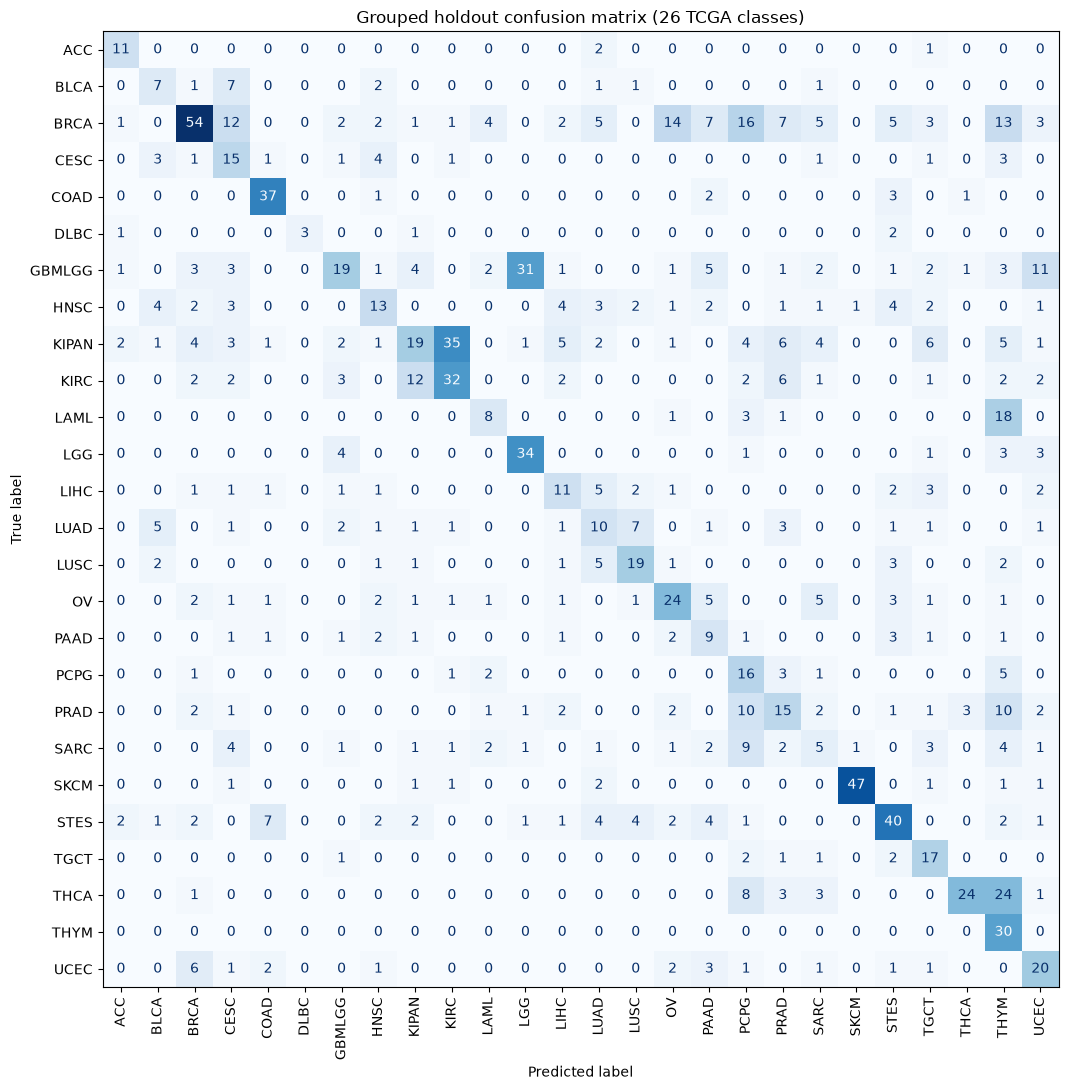

In [6]:
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay
import xgboost as xgb
import matplotlib.pyplot as plt

label_encoder_mut = LabelEncoder().fit(y_train_mut)
y_train_encoded = label_encoder_mut.transform(y_train_mut)
y_valid_encoded = label_encoder_mut.transform(y_valid_mut)
all_classes = label_encoder_mut.classes_
if len(all_classes) != 26:
    raise ValueError(f"학습 분할의 클래스 수가 26이 아닙니다: {len(all_classes)}")

# 클래스별 중요도를 동일하게 반영하는 Macro F1에 맞춰 균형 표본 가중치를 적용합니다.
model_mut = xgb.XGBClassifier(
    n_estimators=300, learning_rate=0.05, max_depth=4,
    min_child_weight=5, subsample=0.8, colsample_bytree=0.6,
    reg_lambda=5.0, objective="multi:softprob", num_class=len(all_classes),
    eval_metric="mlogloss", tree_method="hist", n_jobs=4, random_state=42,
)
train_weights = compute_sample_weight(class_weight="balanced", y=y_train_encoded)
model_mut.fit(X_train_mut, y_train_encoded, sample_weight=train_weights, verbose=False)

# 검증 Macro F1로 부스팅 반복 횟수를 선택하고, 그룹 홀드아웃은 선택 과정에서 사용하지 않습니다.
round_candidates = [n for n in (50, 100, 150, 200, 250, 300) if n <= model_mut.n_estimators]
valid_scores = {}
for n_rounds in round_candidates:
    pred_encoded = model_mut.predict(X_valid_mut, iteration_range=(0, n_rounds))
    pred_labels = label_encoder_mut.inverse_transform(pred_encoded.astype(int))
    valid_scores[n_rounds] = f1_score(y_valid_mut, pred_labels, labels=all_classes, average="macro", zero_division=0)
best_rounds = max(valid_scores, key=valid_scores.get)
print("Validation Macro F1 by boosting rounds:", valid_scores)
print(f"Validation-selected rounds={best_rounds}; Macro F1={valid_scores[best_rounds]:.4f}")

X_dev_mut = pd.concat([X_train_mut, X_valid_mut])
y_dev_mut = pd.concat([y_train_mut, y_valid_mut])
y_dev_encoded = label_encoder_mut.transform(y_dev_mut)
model_mut_final = xgb.XGBClassifier(
    n_estimators=best_rounds, learning_rate=0.05, max_depth=4,
    min_child_weight=5, subsample=0.8, colsample_bytree=0.6,
    reg_lambda=5.0, objective="multi:softprob", num_class=len(all_classes),
    eval_metric="mlogloss", tree_method="hist", n_jobs=4, random_state=42,
)
dev_weights = compute_sample_weight(class_weight="balanced", y=y_dev_encoded)
model_mut_final.fit(X_dev_mut, y_dev_encoded, sample_weight=dev_weights, verbose=False)
holdout_encoded = model_mut_final.predict(X_holdout_mut)
holdout_pred = label_encoder_mut.inverse_transform(holdout_encoded.astype(int))
holdout_macro_f1 = f1_score(y_holdout_mut, holdout_pred, labels=all_classes, average="macro", zero_division=0)
print(f"Grouped holdout Macro F1 (one final evaluation): {holdout_macro_f1:.4f}")
report = pd.DataFrame(classification_report(
    y_holdout_mut, holdout_pred, labels=all_classes, output_dict=True, zero_division=0
)).T.loc[all_classes, ["precision", "recall", "f1-score", "support"]]
display(report)
fig, ax = plt.subplots(figsize=(13, 11))
ConfusionMatrixDisplay.from_predictions(
    y_holdout_mut, holdout_pred, labels=all_classes, xticks_rotation=90,
    cmap="Blues", colorbar=False, ax=ax,
)
ax.set_title("Grouped holdout confusion matrix (26 TCGA classes)")
fig.tight_layout()
plt.show()

가중치 적용 XGBoost는 validation Macro F1이 **0.4307**일 때 200 boosting rounds를 선택했고, 독립적인 그룹 holdout Macro F1은 **0.4366**이었습니다. holdout에서 SKCM F1은 0.904, COAD 0.779, ACC 0.688이었지만 SARC는 0.139, KIPAN 0.257로 낮았습니다. 즉 일부 암종은 잘 구분되지만 26개 클래스 전반의 성능은 아직 제한적입니다. 특히 label collision이 많은 동일 변이 프로필을 그룹 단위로 분리한 점을 고려하면, 이전 베이스라인의 전체 train 학습 결과와 직접 비교할 수 없습니다.

다음 셀에서 동일한 grouped split, class weights, validation 기반 boosting-round 선택으로 기존 방식(유전자 칸별 OrdinalEncoder + XGBoost)을 다시 평가해, 파생변수 추가가 실제 holdout Macro F1을 개선했는지 확인합니다.

In [7]:
from sklearn.preprocessing import OrdinalEncoder

# 원래 접근법을 공정하게 재평가하기 위해 인코더는 학습 행에만 적합합니다.
raw_gene_values = feature_input.loc[:, gene_cols]
ordinal_encoder_fair = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
X_train_ord = ordinal_encoder_fair.fit_transform(raw_gene_values.iloc[train_idx]).astype(np.float32)
X_valid_ord = ordinal_encoder_fair.transform(raw_gene_values.iloc[valid_idx]).astype(np.float32)
X_holdout_ord = ordinal_encoder_fair.transform(raw_gene_values.iloc[holdout_idx]).astype(np.float32)

model_base = xgb.XGBClassifier(
    n_estimators=300, learning_rate=0.05, max_depth=4,
    min_child_weight=5, subsample=0.8, colsample_bytree=0.6,
    reg_lambda=5.0, objective="multi:softprob", num_class=len(all_classes),
    eval_metric="mlogloss", tree_method="hist", n_jobs=4, random_state=42,
)
model_base.fit(X_train_ord, y_train_encoded, sample_weight=train_weights, verbose=False)
base_valid_scores = {}
for n_rounds in (50, 100, 150, 200, 250, 300):
    pred_encoded = model_base.predict(X_valid_ord, iteration_range=(0, n_rounds))
    pred_labels = label_encoder_mut.inverse_transform(pred_encoded.astype(int))
    base_valid_scores[n_rounds] = f1_score(y_valid_mut, pred_labels, labels=all_classes, average="macro", zero_division=0)
best_base_rounds = max(base_valid_scores, key=base_valid_scores.get)

X_dev_ord = ordinal_encoder_fair.transform(raw_gene_values.iloc[np.concatenate([train_idx, valid_idx])]).astype(np.float32)
y_dev_base = label_encoder_mut.transform(y_dev_mut)
model_base_final = xgb.XGBClassifier(
    n_estimators=best_base_rounds, learning_rate=0.05, max_depth=4,
    min_child_weight=5, subsample=0.8, colsample_bytree=0.6,
    reg_lambda=5.0, objective="multi:softprob", num_class=len(all_classes),
    eval_metric="mlogloss", tree_method="hist", n_jobs=4, random_state=42,
)
model_base_final.fit(
    X_dev_ord, y_dev_base,
    sample_weight=compute_sample_weight(class_weight="balanced", y=y_dev_base),
    verbose=False,
)
base_holdout_encoded = model_base_final.predict(X_holdout_ord)
base_holdout_pred = label_encoder_mut.inverse_transform(base_holdout_encoded.astype(int))
base_holdout_macro_f1 = f1_score(y_holdout_mut, base_holdout_pred, labels=all_classes, average="macro", zero_division=0)
comparison = pd.DataFrame({
    "model": ["OrdinalEncoder + XGBoost baseline", "Gene indicators + mutation-derived features + XGBoost"],
    "validation_macro_f1": [base_valid_scores[best_base_rounds], valid_scores[best_rounds]],
    "holdout_macro_f1": [base_holdout_macro_f1, holdout_macro_f1],
    "selected_rounds": [best_base_rounds, best_rounds],
})
display(comparison)
print(f"Holdout Macro F1 difference (derived - baseline): {holdout_macro_f1 - base_holdout_macro_f1:+.4f}")

,model,validation_macro_f1,holdout_macro_f1,selected_rounds
0,OrdinalEncoder + XGBoost baseline,0.356252,0.317317,300
1,Gene indicators + mutation-derived features + ...,0.430696,0.436630,200


Holdout Macro F1 difference (derived - baseline): +0.1193


동일한 그룹 분할에서 OrdinalEncoder + XGBoost는 validation **0.3563**, holdout **0.3173** Macro F1이었습니다. 유전자 존재 indicator와 파생변수를 함께 쓴 모델은 validation **0.4307**, holdout **0.4366**으로, 단순 ordinal baseline보다 holdout에서 **+0.1193** 높았습니다. 다만 두 모델은 원시 문자열 인코딩 방식도 달라졌으므로 이 차이를 파생변수만의 효과로 해석할 수는 없습니다. 다음 ablation에서 gene-presence 4,384개만 쓴 모델을 추가해 아미노산/부담량/경로 파생변수의 추가 이득을 분리합니다.

In [8]:
gene_feature_names = [f"gene_mutated__{gene}" for gene in gene_cols]
X_train_gene = X_train_mut[gene_feature_names]
X_valid_gene = X_valid_mut[gene_feature_names]
X_holdout_gene = X_holdout_mut[gene_feature_names]

gene_only_model = xgb.XGBClassifier(
    n_estimators=300, learning_rate=0.05, max_depth=4,
    min_child_weight=5, subsample=0.8, colsample_bytree=0.6,
    reg_lambda=5.0, objective="multi:softprob", num_class=len(all_classes),
    eval_metric="mlogloss", tree_method="hist", n_jobs=4, random_state=42,
)
gene_only_model.fit(X_train_gene, y_train_encoded, sample_weight=train_weights, verbose=False)
gene_valid_scores = {}
for n_rounds in (50, 100, 150, 200, 250, 300):
    pred_encoded = gene_only_model.predict(X_valid_gene, iteration_range=(0, n_rounds))
    pred_labels = label_encoder_mut.inverse_transform(pred_encoded.astype(int))
    gene_valid_scores[n_rounds] = f1_score(y_valid_mut, pred_labels, labels=all_classes, average="macro", zero_division=0)
best_gene_rounds = max(gene_valid_scores, key=gene_valid_scores.get)

X_dev_gene = pd.concat([X_train_gene, X_valid_gene])
gene_only_final = xgb.XGBClassifier(
    n_estimators=best_gene_rounds, learning_rate=0.05, max_depth=4,
    min_child_weight=5, subsample=0.8, colsample_bytree=0.6,
    reg_lambda=5.0, objective="multi:softprob", num_class=len(all_classes),
    eval_metric="mlogloss", tree_method="hist", n_jobs=4, random_state=42,
)
gene_only_final.fit(
    X_dev_gene, y_dev_encoded,
    sample_weight=compute_sample_weight(class_weight="balanced", y=y_dev_encoded),
    verbose=False,
)
gene_only_pred = label_encoder_mut.inverse_transform(gene_only_final.predict(X_holdout_gene).astype(int))
gene_only_holdout_f1 = f1_score(y_holdout_mut, gene_only_pred, labels=all_classes, average="macro", zero_division=0)
comparison = pd.DataFrame([
    {"model": "OrdinalEncoder + XGBoost baseline", "validation_macro_f1": base_valid_scores[best_base_rounds], "holdout_macro_f1": base_holdout_macro_f1, "selected_rounds": best_base_rounds},
    {"model": "Gene-presence indicators only + XGBoost", "validation_macro_f1": gene_valid_scores[best_gene_rounds], "holdout_macro_f1": gene_only_holdout_f1, "selected_rounds": best_gene_rounds},
    {"model": "Gene indicators + mutation-derived features + XGBoost", "validation_macro_f1": valid_scores[best_rounds], "holdout_macro_f1": holdout_macro_f1, "selected_rounds": best_rounds},
])
display(comparison)
print(f"Full engineered minus gene-only holdout Macro F1: {holdout_macro_f1 - gene_only_holdout_f1:+.4f}")

,model,validation_macro_f1,holdout_macro_f1,selected_rounds
0,OrdinalEncoder + XGBoost baseline,0.356252,0.317317,300
1,Gene-presence indicators only + XGBoost,0.364598,0.323726,300
2,Gene indicators + mutation-derived features + ...,0.430696,0.436630,200


Full engineered minus gene-only holdout Macro F1: +0.1129


## 추천 모델 점수 시각화

아래 그래프는 같은 그룹 분할에서 비교한 세 모델의 validation/holdout Macro F1과 추천 모델의 암종별 holdout F1을 보여줍니다. 클래스별 점수는 모델이 암종마다 다르게 작동하는 정도를 확인하기 위한 것입니다.

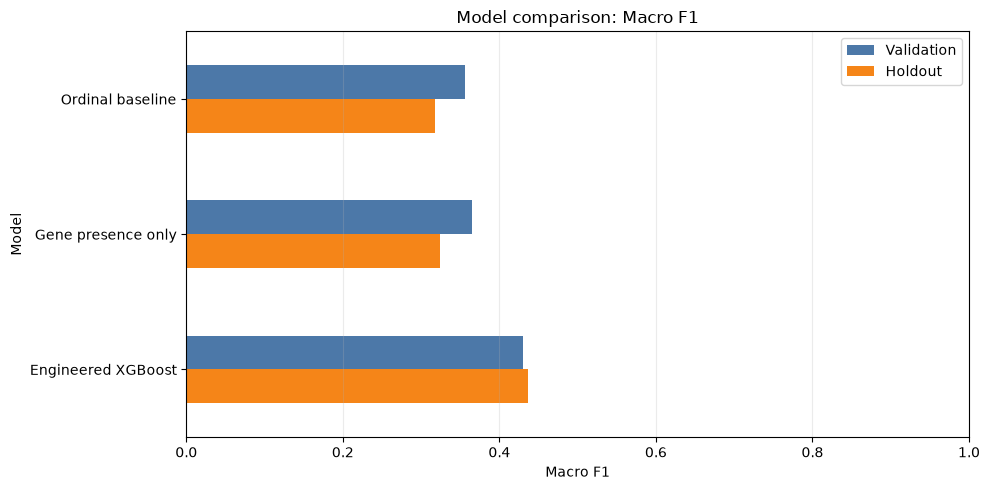

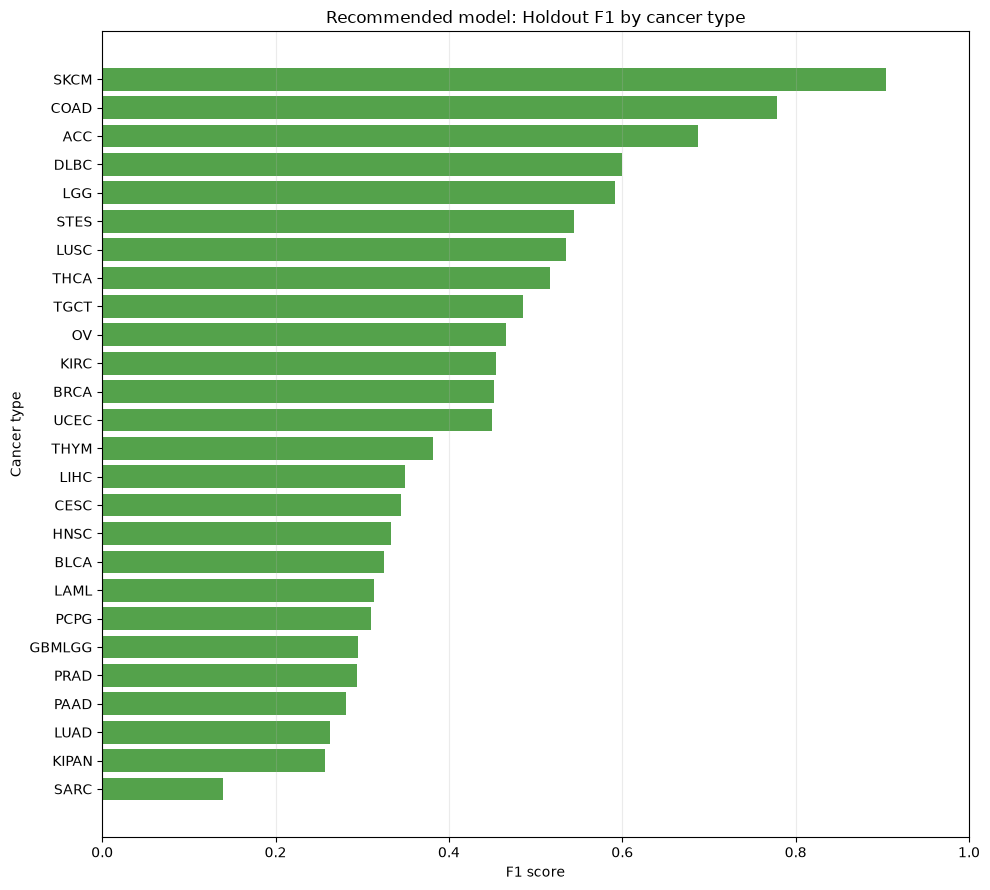

In [12]:
import matplotlib.pyplot as plt

if not {"model", "validation_macro_f1", "holdout_macro_f1"}.issubset(comparison.columns):
    raise ValueError("모델 비교표에 필요한 Macro F1 열이 없습니다.")
if "f1-score" not in report.columns:
    raise ValueError("암종별 평가표에 'f1-score' 열이 없습니다.")

plot_data = comparison.set_index("model")[["validation_macro_f1", "holdout_macro_f1"]]
if len(plot_data) != 3:
    raise ValueError(f"비교할 모델 수가 예상과 다릅니다: {len(plot_data)}")
plot_data.index = ["Ordinal baseline", "Gene presence only", "Engineered XGBoost"]
ax = plot_data.plot(kind="barh", figsize=(10, 5), color=["#4C78A8", "#F58518"])
ax.set_title("Model comparison: Macro F1")
ax.set_xlabel("Macro F1")
ax.set_ylabel("Model")
ax.set_xlim(0, 1)
ax.legend(["Validation", "Holdout"])
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

class_f1 = report["f1-score"].sort_values()
fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(class_f1.index, class_f1.values, color="#54A24B")
ax.set_title("Recommended model: Holdout F1 by cancer type")
ax.set_xlabel("F1 score")
ax.set_ylabel("Cancer type")
ax.set_xlim(0, 1)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

그래프에서 전체 파생변수 모델은 validation 및 holdout 점수가 가장 높으며, 암종별 holdout F1에는 차이가 있음을 확인할 수 있습니다. 성능 비교는 동일한 그룹 분할 결과이므로, 단일 분할을 넘어선 일반화 성능을 확정하려면 반복 grouped cross-validation이 필요합니다.

## 최종 학습 및 submission.csv 생성

검증 데이터에서 선택된 `best_rounds`를 사용해 전체 라벨 데이터로 추천 모델을 다시 학습하고, test 데이터 예측으로 제출 파일을 만듭니다. 기존 `baseline_submission.csv`는 덮어쓰지 않고 별도의 `submission.csv`를 생성합니다.

In [11]:
from pathlib import Path
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight

if not best_rounds:
    raise ValueError("검증 단계에서 선택한 부스팅 반복 횟수(best_rounds)가 없습니다.")

# 학습/테스트 유전자 열이 같은지 확인하고 학습 때의 순서로 맞춥니다.
test_gene_cols = [col for col in test.columns if col.upper() not in ID_NAMES]
if set(gene_cols) != set(test_gene_cols):
    missing_from_test = sorted(set(gene_cols) - set(test_gene_cols))
    extra_in_test = sorted(set(test_gene_cols) - set(gene_cols))
    raise ValueError(
        f"Train/test 유전자 열이 일치하지 않습니다. "
        f"test 누락={missing_from_test[:10]}, test 추가={extra_in_test[:10]}"
    )

X_test_mut = build_mutation_features(test.loc[:, gene_cols], gene_cols)
final_label_encoder = LabelEncoder()
y_all_encoded = final_label_encoder.fit_transform(y_labels.astype(str))
if len(final_label_encoder.classes_) != 26:
    raise ValueError(f"학습 레이블 클래스 수가 26개가 아닙니다: {len(final_label_encoder.classes_)}")

final_model = xgb.XGBClassifier(
    n_estimators=best_rounds, learning_rate=0.05, max_depth=4,
    min_child_weight=5, subsample=0.8, colsample_bytree=0.6,
    reg_lambda=5.0, objective="multi:softprob",
    num_class=len(final_label_encoder.classes_),
    eval_metric="mlogloss", tree_method="hist", n_jobs=4, random_state=42,
)
all_train_weights = compute_sample_weight(class_weight="balanced", y=y_all_encoded)
final_model.fit(X_mut_features, y_all_encoded, sample_weight=all_train_weights, verbose=False)
predicted_labels = final_label_encoder.inverse_transform(final_model.predict(X_test_mut).astype(int))

sample_submission_path = Path(r"C:\AI수업\데이콘과제\암종분류\open\sample_submission.csv")
submission_path = Path(r"C:\AI수업\데이콘과제\암종분류\submission.csv")
submission = pd.read_csv(sample_submission_path)
if len(submission) != len(test):
    raise ValueError(f"제출 템플릿 행 수({len(submission)})와 test 행 수({len(test)})가 다릅니다.")
if "SUBCLASS" not in submission.columns:
    raise KeyError("제출 템플릿에 'SUBCLASS' 열이 없습니다.")
if "ID" in submission.columns and "ID" in test.columns:
    if not submission["ID"].astype(str).equals(test["ID"].astype(str)):
        raise ValueError("제출 템플릿과 test 데이터의 ID 또는 행 순서가 일치하지 않습니다.")

submission["SUBCLASS"] = predicted_labels
submission.to_csv(submission_path, index=False, encoding="utf-8-sig")
print(f"제출 파일 생성 완료: {submission_path}")
print(f"행 수: {len(submission):,} / 예측 클래스 수: {pd.Series(predicted_labels).nunique()}")
display(submission.head())

제출 파일 생성 완료: C:\AI수업\데이콘과제\암종분류\submission.csv
행 수: 2,546 / 예측 클래스 수: 26


,ID,SUBCLASS
0,TEST_0000,STES
1,TEST_0001,STES
2,TEST_0002,SARC
3,TEST_0003,LGG
4,TEST_0004,LUSC


최종 제출 셀은 검증에서 선택된 **200회**로 전체 라벨 데이터에 모델을 다시 학습한 뒤, test **2,546명**을 예측했습니다. `submission.csv`에는 `ID`, `SUBCLASS` 두 열과 2,546행이 있으며, 26개 클래스가 모두 예측 결과에 포함되었습니다. test 정답은 없으므로 이 파일만으로 test Macro F1을 계산할 수는 없습니다.

### Q&A

- **우선 추천할 모델은 무엇인가요?** 동일한 프로필 그룹 분할에서 유전자 변이 여부와 단백질 변이 표기 기반 파생변수를 함께 사용한 class-weighted XGBoost를 우선 후보로 추천합니다. 단일 분할 결과이므로 일반화 성능이 확정된 것은 아닙니다.
- **아미노산 치환만으로 공식 변이 시그니처를 재현할 수 있나요?** 아니요. 염기 치환 종류와 주변 염기 문맥이 없어 COSMIC SBS/DBS 시그니처를 계산할 수 없습니다. 아미노산 치환 패턴은 단백질 수준의 근사 요약입니다.

### Data Analysis Key Findings

- 같은 그룹 분할에서 OrdinalEncoder 베이스라인의 validation/holdout Macro F1은 **0.3563/0.3173**, 유전자 변이 여부만 사용한 모델은 **0.3646/0.3237**, 파생변수 포함 모델은 **0.4307/0.4366**이었습니다. 파생변수 모델은 유전자 여부만 사용한 모델보다 holdout에서 **+0.1129** 높았습니다.
- 암종별 holdout F1은 고르지 않았습니다. SKCM **0.904**, COAD **0.779**, ACC **0.688**이 높았고, SARC **0.139**, KIPAN **0.257**은 낮았습니다.
- 전체 라벨 데이터로 재학습해 `submission.csv`를 생성했습니다. test 2,546행, `ID`와 `SUBCLASS` 두 열이며, 예측값에 26개 클래스가 모두 포함되었습니다. test 정답이 없어 test Macro F1은 계산하지 않았습니다.

### Insights or Next Steps

- 단일 grouped holdout 결과의 변동성을 확인하기 위해 여러 seed의 grouped cross-validation으로 Macro F1 평균과 편차를 평가하세요.
- 제출 전 [submission.csv](</C:/AI수업/데이콘과제/암종분류/submission.csv>)의 열 순서와 행 수를 대회 제출 규격과 대조하세요.